### **Student Information**
GitHub ID: hinoki14

Kaggle name: hinoki04

Kaggle private scoreboard snapshot:  
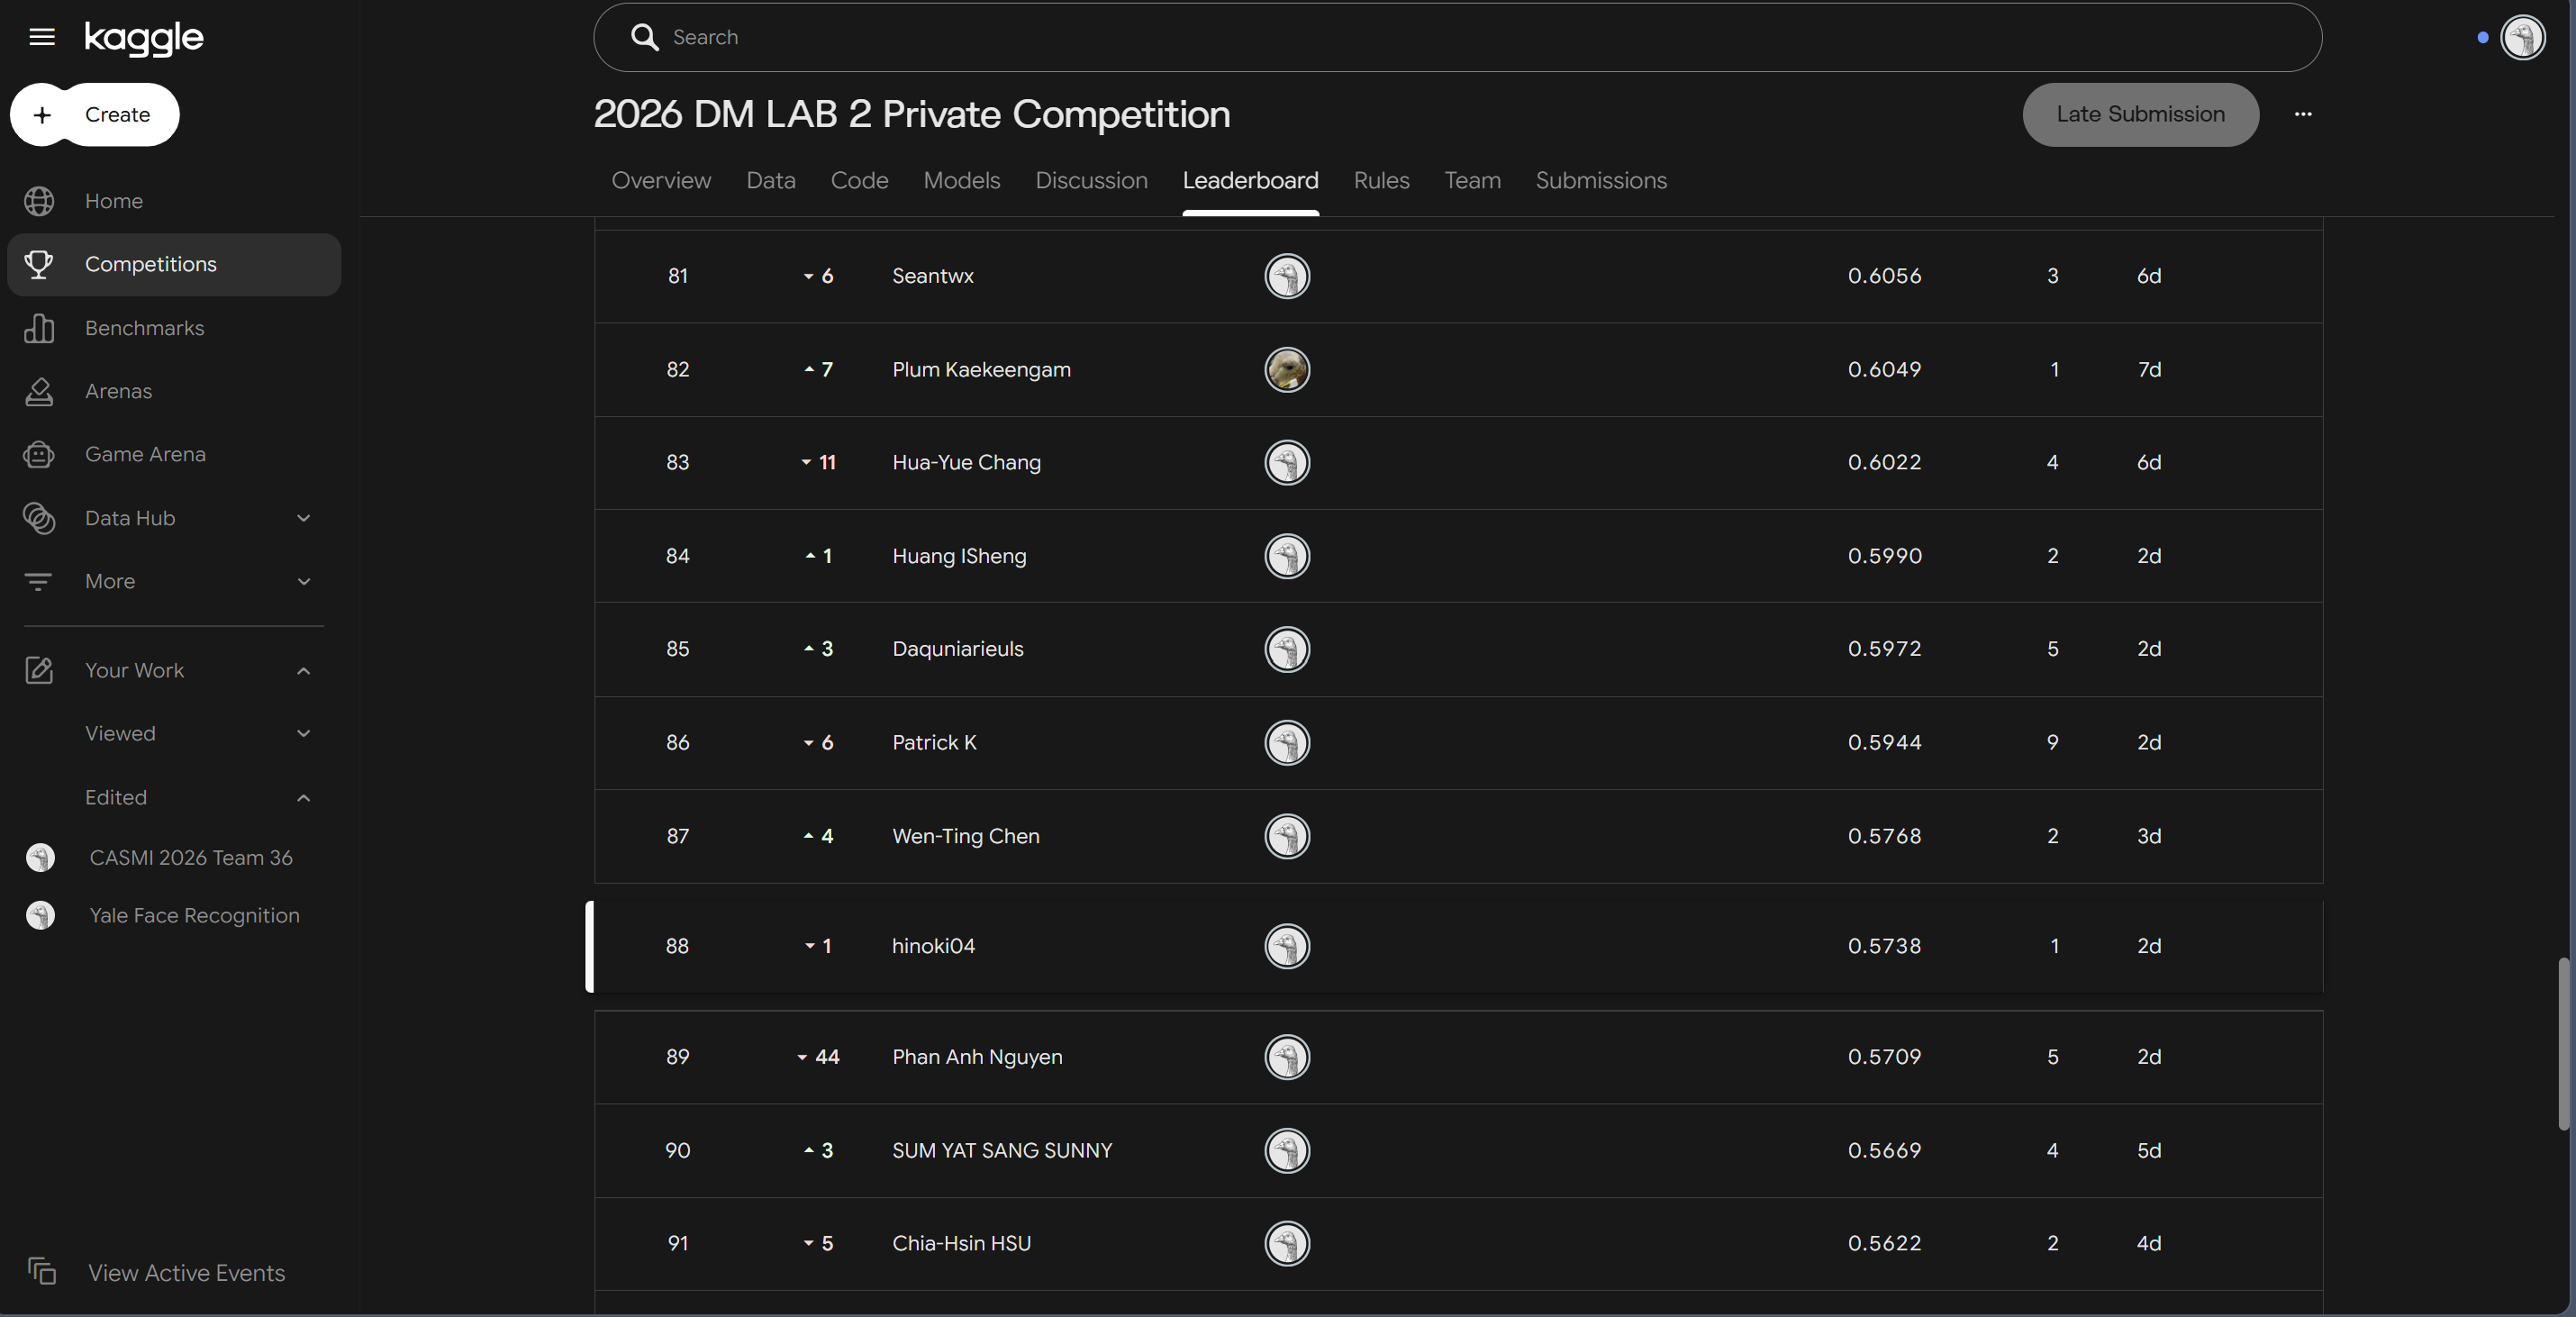

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---

Next you will find the template report with some simple markdown syntax explanations, use it to structure your content.

You can delete the syntax suggestions after you use them.

---

***

# **Project Report**

---

## 1. Model Development (10 pts Required)

**Task.** Predict one of 6 emotions (anger, disgust, fear, sadness, surprise, joy) for short posts. Train: 3,360 labelled posts. Test: 1,440 posts. Kaggle metric: Mean F1. Baseline: 0.5.

**Final model in one line:** word and character TF-IDF concatenated with `all-mpnet-base-v2` sentence embeddings, classified by a class-balanced Linear SVM (C = 0.1).

**Results:** public leaderboard score **0.5779**, private leaderboard score **0.5738**, private leaderboard rank **88**.

### 1.1 Preprocessing Steps

* **Joined the three data files.** `final_posts.json` holds `post_id` and `text` for all 4,800 posts, `emotion.csv` holds the labels of the training posts, and `sampleSubmission.csv` lists the test ids in the order the submission needs. Training data is `final_posts.json` joined with `emotion.csv` on `post_id`; test data is the posts whose ids appear in the sample submission, kept in the sample's order. The files are read explicitly as UTF-8, because the default encoding on Windows cannot decode some characters in the posts.
* **Checked the data.** No missing or empty texts, every training id has exactly one label, and the test ids match the identification file and the sample submission exactly.
* **Class balance.** The labels are imbalanced (joy 875, anger 674, sadness 628, disgust 454, surprise 441, fear 288 in the training set), which is why the final classifier uses `class_weight="balanced"`.
* **Duplicates.** 50 training texts appear more than once. I checked for them but did not remove them.
* **No manual text cleaning.** The raw text goes into the vectorisers. `TfidfVectorizer` lowercases the text by default, and the sentence-embedding model receives the text unchanged, because it was trained on natural text. I did not strip punctuation, emoji or hashtags, since character n-grams and the embedding model can use them.

### 1.2 Feature Engineering Steps

The final feature vector is three blocks placed side by side:

1. **Word TF-IDF**, unigrams and bigrams (`ngram_range=(1, 2)`, `min_df=2`, `sublinear_tf=True`). It captures which words and short phrases a post uses.
2. **Character TF-IDF**, 2 to 5 character n-grams inside word boundaries (`analyzer="char_wb"`, `min_df=2`, `sublinear_tf=True`). It is more robust to spelling variants, elongated words and hashtags.
3. **Sentence embeddings** from `all-mpnet-base-v2` (768 dimensions, L2-normalised), multiplied by a weight `a` (1.0 in the final model). It captures what a post means, even when it shares no words with the training posts.

The TF-IDF blocks (35,032 columns) are sparse and the embedding block (768 columns) is dense. They are joined with `scipy.sparse.hstack` into a matrix of 35,800 columns.

**Why combine them.** Each representation alone was weak and about equal. In 5-fold cross-validation on the training data, TF-IDF alone scored a macro F1 of 0.512 and the embeddings alone (with logistic regression) scored 0.5086. Together they scored 0.5653, a gain of about 0.05. That is much larger than the 0.006 spread across the nine nearby settings I tried later (section 1.3). This is consistent with the two representations capturing different information, although I did not run an experiment to isolate why.

### 1.3 Explanation of Your Model

* **Classifier:** `LinearSVC` (linear support vector machine) with `C = 0.1` and `class_weight="balanced"`. It fits one linear boundary per emotion, and works well on high-dimensional sparse text features. A small C means strong regularisation, which suits a feature space with far more columns than training posts. `class_weight="balanced"` raises the cost of mistakes on small classes such as fear.
* **Model selection:** 5-fold stratified cross-validation (`random_state=0`) on the training set, comparing macro F1. I did not choose settings by looking at the leaderboard.

| Setup | CV macro F1 |
|---|---|
| TF-IDF only, Linear SVM (C = 0.3) | 0.512 |
| Embeddings only, Logistic Regression (C = 1) | 0.5086 |
| **TF-IDF + embeddings, Linear SVM (a = 1, C = 0.1)** | **0.5653** |

I then searched a small grid around the chosen setting (a in 0.5, 0.75, 1 and C in 0.03, 0.05, 0.1). All nine settings scored between 0.5637 and 0.5693, so the surface is flat. The best of the nine (a = 0.75, C = 0.05, 0.5693) differs from the chosen one by 0.004, which is noise, and picking the best of nine would overstate the true score. I kept a = 1 and C = 0.1. 

**Grid search (5-fold CV, macro F1).** Embedding weight a (rows) against SVM C (columns). The first grid (a = 1, 2, 3 with C = 0.1, 0.3) is on the left, the second (a = 0.5, 0.75, 1 with C = 0.03, 0.05, 0.1) on the right.

| a \ C | 0.03 | 0.05 | 0.1 | 0.3 |
|---|---|---|---|---|
| 0.5 | 0.5653 | 0.5646 | 0.5643 | not run |
| 0.75 | 0.5680 | **0.5693** | 0.5670 | not run |
| 1 | 0.5681 | 0.5637 | **0.5653** (chosen) | 0.5593 |
| 2 | not run | not run | 0.5486 | 0.5444 |
| 3 | not run | not run | 0.5295 | 0.5252 |

A larger embedding weight hurts (a = 2 and 3 are clearly worse), while a between 0.5 and 1 with C between 0.03 and 0.1 gives scores within 0.006 of each other.

**Results.**

| | Score |
|---|---|
| Cross-validation macro F1 (training set) | 0.5653 |
| Public leaderboard | 0.5779 |
| Private leaderboard | 0.5738 |

Both leaderboard scores are above the 0.5 baseline. The public and private scores differ by only 0.004 and are close to the cross-validation estimate, so the model did not appear to overfit the public part of the test set. Re-running this notebook from scratch reproduced the cross-validation score of 0.5653 exactly.

**Caveats.**
* In the combined experiments, the TF-IDF vocabulary was fitted on the whole training set before cross-validation, whereas the 0.512 baseline fitted it inside each fold. This favours the combined model slightly. The gain is much larger than that effect, but the exact size of the improvement is not certain. The leaderboard scores, which come from data the model never saw, are consistent with the cross-validation estimate.
* Every setting was chosen by cross-validation, never by the leaderboard.

### 1.4 AI Prompts, what and why you decide to use that technique that suggest by AI

I used Claude (Anthropic) as an assistant for the competition. The prompts below are listed in order and summarised where they were long. [Delete this bracket. Replace any summary with your exact wording if the course requires verbatim prompts, and add any other AI tool you used.]

| # | Prompt (summary) | What the AI suggested | What I did and why |
|---|---|---|---|
| 1 | Uploaded the competition zip and asked what is in it. | Join `final_posts.json` with `emotion.csv`; 6 classes, imbalanced; a quick TF-IDF + Linear SVM baseline scored macro F1 of about 0.50 to 0.53 on a validation split. | Used the join. Kept the imbalance in mind for the classifier. |
| 2 | Said the competition closes in 2 hours; pasted the Overview and Evaluation text. | Submit a safe TF-IDF + SVM file first; noted the submission column is `id` on the Evaluation page but `post_id` in the sample file. | Submitted a safe file first, and prepared both column names. |
| 3 | Asked for the embedding script as a Jupyter notebook to run on Google Colab. | A Colab notebook: `all-mpnet-base-v2` embeddings plus Logistic Regression, choosing C by 5-fold CV. | Ran it. Result: CV macro F1 0.5086, no better than TF-IDF (0.512), so I did not submit embeddings alone. |
| 4 | Pasted those CV results. | Concatenate TF-IDF with the embeddings and choose the weight and C by CV. | Adopted it: CV macro F1 rose to 0.5653. |
| 5 | Pasted a second grid of results around the best setting. | The scores were flat (0.5637 to 0.5693), so do not re-tune for a 0.004 gain. | Kept a = 1, C = 0.1 to avoid overfitting to the cross-validation. |
| 6 | Reported the leaderboard scores and asked what to record for the report and the code folder. | Record the exact configuration; put the code and the report in this notebook; check that the files are complete before pushing. | Wrote this report. The final scores were public 0.5779 and private 0.5738. |
| 7 | Pasted a `UnicodeDecodeError` from loading `final_posts.json` on Windows. | Read the files with `encoding="utf-8"`. | Applied the fix in the preprocessing cell. |

**What I decided not to use:** embeddings alone (not better than TF-IDF), and the slightly higher grid maximum (a difference within noise).

---

**`From here on starts the code section for the competition.`**

---

# **Competition Code**

The cells below reproduce the final model (public score 0.5779). They expect the four competition files (`final_posts.json`, `emotion.csv`, `data_identification.csv`, `sampleSubmission.csv`) in `DATA_DIR`. Step 2 downloads a sentence-embedding model, so run it on a GPU runtime (Colab or Kaggle) with internet access; the embedding step takes a few minutes there.

## 1. Preprocessing Steps

In [3]:
import json
import numpy as np
import pandas as pd

DATA_DIR = "."   # folder that contains the four competition files

with open(f"{DATA_DIR}/final_posts.json", encoding="utf-8") as f:
    posts = pd.DataFrame(json.load(f))                                    # post_id, text (all 4,800 posts)
emo    = pd.read_csv(f"{DATA_DIR}/emotion.csv", encoding="utf-8")         # post_id, label (train only)
ident  = pd.read_csv(f"{DATA_DIR}/data_identification.csv", encoding="utf-8")   # which ids are train / test
sample = pd.read_csv(f"{DATA_DIR}/sampleSubmission.csv", encoding="utf-8")      # test ids in the required order

# --- Join into a training table and a test table ----------------------------------
train = posts.merge(emo, on="post_id", how="inner")                       # 3,360 labelled posts
test_ids = sample.iloc[:, 0]                                              # first column holds the test ids
test = posts.set_index("post_id").loc[test_ids].reset_index()             # 1,440 test posts, in sample order

# --- Sanity checks --------------------------------------------------------------
assert len(train) == 3360 and len(test) == 1440
assert set(test.post_id) == set(ident.loc[ident["set"] == "test", "post_id"])   # test ids match the identification file
assert posts.text.notna().all() and (posts.text.str.strip() != "").all()        # no empty texts
print("train:", train.shape, "| test:", test.shape)
print("labels:", train.label.value_counts().to_dict())                          # imbalanced: fear is the smallest class
print("duplicate training texts (kept, not removed):", int(train.text.duplicated().sum()))

# No manual text cleaning: TfidfVectorizer lowercases by default, and the embedding model
# receives the raw text.

train: (3360, 3) | test: (1440, 2)
labels: {'joy': 875, 'anger': 674, 'sadness': 628, 'disgust': 454, 'surprise': 441, 'fear': 288}
duplicate training texts (kept, not removed): 50


## 2. Feature Engineering Steps

In [4]:
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_union

# Block 1 + 2: word (1-2 gram) and character (2-5 gram) TF-IDF, fitted on the training posts only.
tfidf = make_union(
    TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2),
    TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, min_df=2),
)
T_train = tfidf.fit_transform(train.text)
T_test = tfidf.transform(test.text)
print("TF-IDF shapes:", T_train.shape, T_test.shape)

TF-IDF shapes: (3360, 35032) (1440, 35032)


In [5]:
from sentence_transformers import SentenceTransformer

try:
    import torch
    device = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    device = "cpu"
print("device:", device)

# Block 3: sentence embeddings (meaning of the whole post), L2-normalised.
EMBED_MODEL = "all-mpnet-base-v2"
encoder = SentenceTransformer(EMBED_MODEL, device=device)
E_train = encoder.encode(train.text.tolist(), batch_size=64, show_progress_bar=True, normalize_embeddings=True)
E_test = encoder.encode(test.text.tolist(), batch_size=64, show_progress_bar=True, normalize_embeddings=True)
print("embedding shapes:", E_train.shape, E_test.shape)

device: cpu


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

C:\Users\user\DM2026Lab2\DM2026-Lab2-Announcement\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\user\.cache\huggingface\hub\models--sentence-transformers--all-mpnet-base-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

... (9 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/53 [00:00<?, ?it/s]

Batches:   0%|          | 0/23 [00:00<?, ?it/s]

embedding shapes: (3360, 768) (1440, 768)


In [6]:
# Put the three blocks side by side: sparse TF-IDF columns + dense embedding columns.
EMB_WEIGHT = 1.0     # the weight "a" in the report: scale of the embedding block relative to TF-IDF
X_train = hstack([T_train, csr_matrix(E_train * EMB_WEIGHT)]).tocsr()
X_test = hstack([T_test, csr_matrix(E_test * EMB_WEIGHT)]).tocsr()
print("combined feature matrix:", X_train.shape, X_test.shape)

combined feature matrix: (3360, 35800) (1440, 35800)


## 3. Model Implementation Steps

In [7]:
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score

C_SVM = 0.1
skf = StratifiedKFold(5, shuffle=True, random_state=0)

# 5-fold cross-validation of the final configuration (this is how settings were chosen, not the leaderboard).
model = LinearSVC(C=C_SVM, class_weight="balanced")      # "balanced" raises the cost of errors on small classes
cv_pred = cross_val_predict(model, X_train, train.label, cv=skf)
print(f"CV macro F1 (TF-IDF + embeddings, C={C_SVM}): {f1_score(train.label, cv_pred, average='macro'):.4f}")
print("(recorded earlier: 0.5653; the TF-IDF vocabulary is fitted on all training posts before CV, so this is slightly optimistic)")

CV macro F1 (TF-IDF + embeddings, C=0.1): 0.5653
(recorded earlier: 0.5653; the TF-IDF vocabulary is fitted on all training posts before CV, so this is slightly optimistic)


In [8]:
# Reference points from the report (TF-IDF only, vectoriser fitted inside each fold). Takes about a minute.
from sklearn.pipeline import make_pipeline

tfidf_only = make_pipeline(
    make_union(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2),
               TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, min_df=2)),
    LinearSVC(C=0.3, class_weight="balanced"),
)
p = cross_val_predict(tfidf_only, train.text, train.label, cv=skf)
print(f"CV macro F1 (TF-IDF only, C=0.3): {f1_score(train.label, p, average='macro'):.4f}   (recorded earlier: 0.512)")

CV macro F1 (TF-IDF only, C=0.3): 0.5121   (recorded earlier: 0.512)


In [9]:
# Fit on all training posts and write the submission file.
final = LinearSVC(C=C_SVM, class_weight="balanced").fit(X_train, train.label)
pred = final.predict(X_test)

# The Evaluation page asks for columns "id,label"; the sample file used "post_id,label". Both are written.
out = pd.DataFrame({"id": test.post_id, "label": pred})
assert len(out) == 1440 and out["id"].is_unique
out.to_csv("submission_combined_id.csv", index=False)
out.rename(columns={"id": "post_id"}).to_csv("submission_combined_post_id.csv", index=False)
print(out.label.value_counts().to_dict())

{'joy': 402, 'anger': 314, 'sadness': 252, 'surprise': 181, 'disgust': 166, 'fear': 125}
